# 09 - Cierre del EDA y priorización de KPIs

- Cierra la etapa descriptiva y reúne las conclusiones de PE2.
- Vuelve explícitas las unidades, denominadores, cobertura y limitaciones de cada KPI.
- Prioriza indicadores por las tres decisiones del Instituto de Vivienda.
- Identifica comunas para diagnóstico adicional con reglas transparentes; no es un índice normativo.
- Insumos: base enriquecida, KPIs por barrio y comuna, síntesis de hipótesis de 08.
- Salidas: tablas de jerarquización y señales exploratorias en `data/processed/reports/`.

## 1. Carga y controles

- Se reutilizan exclusivamente las salidas documentadas de 07 y 08.
- Se comprueba la clave publicación-operación y la cobertura del universo territorial.
- Las cantidades de avisos no se interpretan como proporciones del stock.

In [8]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import config



REPORTS = config.REPORTS_DIR
base = pd.read_csv(
    config.PROCESSED_DIR / "df_publicaciones_enriquecidas_v1.csv",
    low_memory=False,
    dtype={"id_publicacion": str}
)
kb = pd.read_csv(config.PROCESSED_DIR / "kpis_barrio_v1.csv")
kc = pd.read_csv(config.PROCESSED_DIR / "kpis_comuna_v1.csv")
sintesis_08 = pd.read_csv(REPORTS / "eda08_sintesis_hipotesis_v1.csv")

assert not base.duplicated(["id_publicacion", "tipo_operacion_norm"]).any()
assert kb["barrio_oficial"].nunique() == len(kb)
assert kc["comuna"].nunique() == len(kc)

print("Base enriquecida:", base.shape)
print("Barrios con KPI:", kb["barrio_oficial"].nunique())
print("Comunas con KPI:", kc["comuna"].nunique())
display(sintesis_08)

Base enriquecida: (67887, 90)
Barrios con KPI: 48
Comunas con KPI: 15


,hipotesis,tema,unidad,evidencia,lectura,limitaciones
0,H1,Atractivo turístico y alquiler temporario,barrio (48) y comuna (15),Cultura rho = 0.85 (barrio) y 0.86 (comuna); g...,Evidencia a favor,Confundida con la centralidad (el subte tambié...
1,H2a,Tamaño del hogar y tipología,comuna (15),"rho entre -0,50 y 0,01 según operación; IC inc...",Sin evidencia,Poco poder (15 comunas); aproximación débil al...
2,H2b,Servicios y oferta,comuna (15),"Alquiler por 1.000 viviendas: cultura 0,69, ga...",Evidencia parcial,Sin corrección por comparaciones múltiples; lo...
3,H3,Transporte y precio,publicación (~45.000),Efecto por 100 m más lejos: venta +0.8% (IC 0....,"Sin apoyo (signo contrario, efecto pequeño)",Distancia en línea recta; geocodificación del ...
4,H4,"Temporario, disponibilidad y precio",comuna (15),Airbnb vs. precio del alquiler rho = 0.91; vs....,No evaluable,Los precios acompañan pero por centralidad; la...


## 2. De hipótesis a evidencia utilizable

- Se conserva el estado de cada hipótesis del notebook 08.
- Se separa señal observada de evidencia insuficiente.
- En H2a, el tamaño medio del hogar es un proxy indirecto; no mide hogares unipersonales.
- H4 no permite concluir desplazamiento ni sustitución con datos transversales.

In [9]:
display(sintesis_08[["hipotesis", "unidad", "evidencia", "lectura", "limitaciones"]])
sintesis_08.to_csv(REPORTS / "pe3_sintesis_hipotesis_v1.csv", index=False)

,hipotesis,unidad,evidencia,lectura,limitaciones
0,H1,barrio (48) y comuna (15),Cultura rho = 0.85 (barrio) y 0.86 (comuna); g...,Evidencia a favor,Confundida con la centralidad (el subte tambié...
1,H2a,comuna (15),"rho entre -0,50 y 0,01 según operación; IC inc...",Sin evidencia,Poco poder (15 comunas); aproximación débil al...
2,H2b,comuna (15),"Alquiler por 1.000 viviendas: cultura 0,69, ga...",Evidencia parcial,Sin corrección por comparaciones múltiples; lo...
3,H3,publicación (~45.000),Efecto por 100 m más lejos: venta +0.8% (IC 0....,"Sin apoyo (signo contrario, efecto pequeño)",Distancia en línea recta; geocodificación del ...
4,H4,comuna (15),Airbnb vs. precio del alquiler rho = 0.91; vs....,No evaluable,Los precios acompañan pero por centralidad; la...


## 3. Jerarquía de KPIs

- Criterios: vínculo con una decisión, denominador interpretable, cobertura y limitaciones.
- La tabla es una priorización metodológica; no asigna pesos ni agrega dimensiones en un índice único.
- La participación de publicaciones describe la muestra recolectada, no el mercado completo.

In [10]:
catalogo_kpis = pd.DataFrame([
    ["Disponibilidad residencial publicada", "alquiler_por_1000_viviendas", "Comuna", "Fortalecer alquiler permanente", "Conteo de avisos / viviendas Censo 2022; no es stock disponible"],
    ["Concentración temporaria", "airbnb_por_1000_viviendas; airbnb_por_km2", "Comuna / barrio", "Monitorear alquiler temporario", "Airbnb es una fuente específica y un corte de 2026"],
    ["Presión temporaria observada", "pct_viviendas_uso_temporal; brecha Airbnb/permanente", "Comuna / barrio", "Monitorear y producir información", "Censo 2022 y publicaciones tienen fechas y universos distintos"],
    ["Adecuación tipológica", "participación 1-2 ambientes; tamano_medio_hogar", "Comuna", "Priorizar intervención habitacional", "Tamaño medio del hogar es un proxy, no composición individual"],
    ["Accesibilidad urbana", "dist_transporte_masivo_m; densidades de servicios", "Publicación / barrio", "Priorizar infraestructura", "Distancias lineales y cobertura desigual por fuente"],
    ["Asequibilidad/precio publicado", "mediana_precio_m2_venta_usd; mediana_precio_m2_alquiler_usd", "Barrio", "Orientar diagnóstico habitacional", "Precios pedidos; no son precios de cierre ni ingresos de hogares"],
], columns=["dimension", "kpi", "unidad", "decision_informada", "limitacion_clave"])
display(catalogo_kpis)
catalogo_kpis.to_csv(REPORTS / "pe3_jerarquia_kpis_v1.csv", index=False)

# Perfil urbano independiente de los precios, para evitar circularidad en la segmentación.
features_urbanas = [
    "densidad_subte_km2", "densidad_tren_km2", "densidad_metrobus_km2",
    "densidad_hospitales_km2", "densidad_educacion_km2",
    "densidad_culturales_km2", "densidad_gastronomia_km2",
    "densidad_espacios_verdes_km2", "pct_superficie_verde"
]
features_urbanas = [c for c in features_urbanas if c in kb.columns]
perfil_barrios = kb[["barrio_oficial"] + features_urbanas].copy()
perfil_barrios.to_csv(config.PROCESSED_DIR / "pe3_features_barrios_v1.csv", index=False)
print("Perfil urbano para reducción de dimensionalidad:", perfil_barrios.shape)

,dimension,kpi,unidad,decision_informada,limitacion_clave
0,Disponibilidad residencial publicada,alquiler_por_1000_viviendas,Comuna,Fortalecer alquiler permanente,Conteo de avisos / viviendas Censo 2022; no es...
1,Concentración temporaria,airbnb_por_1000_viviendas; airbnb_por_km2,Comuna / barrio,Monitorear alquiler temporario,Airbnb es una fuente específica y un corte de ...
2,Presión temporaria observada,pct_viviendas_uso_temporal; brecha Airbnb/perm...,Comuna / barrio,Monitorear y producir información,Censo 2022 y publicaciones tienen fechas y uni...
3,Adecuación tipológica,participación 1-2 ambientes; tamano_medio_hogar,Comuna,Priorizar intervención habitacional,"Tamaño medio del hogar es un proxy, no composi..."
4,Accesibilidad urbana,dist_transporte_masivo_m; densidades de servicios,Publicación / barrio,Priorizar infraestructura,Distancias lineales y cobertura desigual por f...
5,Asequibilidad/precio publicado,mediana_precio_m2_venta_usd; mediana_precio_m2...,Barrio,Orientar diagnóstico habitacional,Precios pedidos; no son precios de cierre ni i...


Perfil urbano para reducción de dimensionalidad: (48, 10)


## 4. Señal exploratoria para diagnóstico comunal

- Se consideran conjuntamente concentración de Airbnb, baja oferta permanente publicada relativa a viviendas y alquiler mediano elevado.
- Los umbrales son cuartiles internos del corte disponible, no metas de política.
- La intersección identifica casos para investigar; no acredita déficit, desplazamiento ni necesidad de una intervención específica.
- Se informa el número de comunas y se muestran los valores continuos para evitar que el semáforo oculte magnitudes.

Comunas evaluables: 15 de 15
Comunas con las tres señales: 0


,airbnb_por_1000_viviendas,alquiler_por_1000_viviendas,mediana_alquiler_usd_m2_mes,senales_presentes,candidata_diagnostico_adicional
comuna,,,,,
14,21.37,9.49,15.89,2,False
1,15.28,13.98,16.67,2,False
2,12.30,9.37,14.71,2,False
13,6.54,9.55,15.57,2,False
4,1.36,2.35,11.79,1,False
10,0.43,3.61,11.24,1,False
9,0.20,2.78,11.30,1,False
8,0.03,1.37,9.01,1,False
15,4.97,6.11,13.75,0,False


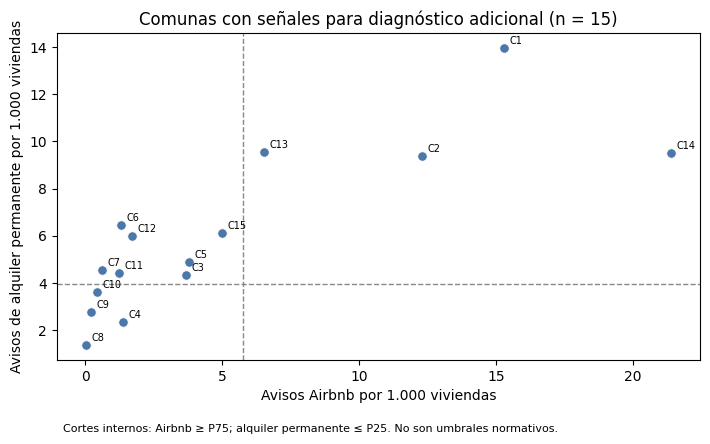

In [11]:
alquiler_comuna = (
    base[(base["tipo_operacion_norm"] == "alquiler")
         & base["precio_m2_usd"].notna()
         & ~base["precio_m2_usd_fuera_rango_flag"]]
    .groupby("comuna_oficial")["precio_m2_usd"].median()
)
alquiler_comuna.index = pd.to_numeric(alquiler_comuna.index, errors="coerce")
diag = kc.set_index("comuna").copy()
diag["mediana_alquiler_usd_m2_mes"] = alquiler_comuna
diag = diag.dropna(subset=[
    "airbnb_por_1000_viviendas",
    "alquiler_por_1000_viviendas",
    "mediana_alquiler_usd_m2_mes"
])
diag["airbnb_alto"] = diag["airbnb_por_1000_viviendas"] >= diag["airbnb_por_1000_viviendas"].quantile(.75)
diag["alquiler_publicado_bajo"] = diag["alquiler_por_1000_viviendas"] <= diag["alquiler_por_1000_viviendas"].quantile(.25)
diag["alquiler_caro"] = diag["mediana_alquiler_usd_m2_mes"] >= diag["mediana_alquiler_usd_m2_mes"].quantile(.75)
diag["senales_presentes"] = diag[["airbnb_alto", "alquiler_publicado_bajo", "alquiler_caro"]].sum(axis=1)
diag["candidata_diagnostico_adicional"] = diag["senales_presentes"] == 3

print("Comunas evaluables:", len(diag), "de", len(kc))
print("Comunas con las tres señales:", int(diag["candidata_diagnostico_adicional"].sum()))
display(diag[[
    "airbnb_por_1000_viviendas", "alquiler_por_1000_viviendas",
    "mediana_alquiler_usd_m2_mes", "senales_presentes",
    "candidata_diagnostico_adicional"
]].sort_values(["senales_presentes", "airbnb_por_1000_viviendas"], ascending=[False, False]).round(2))

fig, ax = plt.subplots(figsize=(7.2, 4.6))
for comuna, fila in diag.iterrows():
    color = "#c45a46" if fila["candidata_diagnostico_adicional"] else "#4b78a8"
    ax.scatter(fila["airbnb_por_1000_viviendas"], fila["alquiler_por_1000_viviendas"],
               color=color, s=48, edgecolor="white", linewidth=.7)
    ax.annotate("C" + str(int(comuna)),
                (fila["airbnb_por_1000_viviendas"], fila["alquiler_por_1000_viviendas"]),
                xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.axvline(diag["airbnb_por_1000_viviendas"].quantile(.75), color="#888888", linestyle="--", linewidth=1)
ax.axhline(diag["alquiler_por_1000_viviendas"].quantile(.25), color="#888888", linestyle="--", linewidth=1)
ax.set_xlabel("Avisos Airbnb por 1.000 viviendas")
ax.set_ylabel("Avisos de alquiler permanente por 1.000 viviendas")
ax.set_title("Comunas con señales para diagnóstico adicional (n = {})".format(len(diag)))
ax.text(.01, -.22, "Cortes internos: Airbnb ≥ P75; alquiler permanente ≤ P25. No son umbrales normativos.",
        transform=ax.transAxes, fontsize=8)
plt.tight_layout()
plt.show()
diag.reset_index().to_csv(REPORTS / "pe3_senales_priorizacion_comunas_v1.csv", index=False)

### Análisis e Interpretación del Gráfico de Diagnóstico Comunal

#### 1. Estructura y Cuadrantes del Gráfico
El gráfico de dispersión analiza la relación entre dos métricas normalizadas por cada $1.000$ viviendas para las 15 comunas de CABA[cite: 1]:
* **Eje X (Avisos de Airbnb por 1.000 viviendas):** Mide la densidad de la oferta turística relativa[cite: 1]. La línea vertical discontinua marca el **Percentil 75** (aprox. $5{,}8$ avisos / $1.000$ viviendas)[cite: 1].
* **Eje Y (Avisos de alquiler permanente por 1.000 viviendas):** Mide la densidad de oferta residencial publicada[cite: 1]. La línea horizontal discontinua marca el **Percentil 25** (aprox. $4{,}0$ avisos / $1.000$ viviendas)[cite: 1].

---

#### 2. Hallazgos Clave e Interpretación

* **Ausencia de comunas con las 3 señales simultáneas:**
  Ningún punto en la gráfica aparece resaltado en rojo (`candidata_diagnostico_adicional == True`)[cite: 1]. El cuadrante inferior derecho (alta presencia de Airbnb y muy baja oferta de alquiler tradicional) se encuentra **completamente vacío**[cite: 1]. Esto indica que ninguna comuna de la CABA cumple en simultáneo con ser de alta penetración turística ($\ge P75$), baja oferta publicada ($\le P25$) y de valor mediano por $m^2$ en el cuartil superior[cite: 1].

* **Comunas de Alta Turistificación (Cuadrante Superior Derecho - C1, C2, C13, C14):**
  Las comunas con mayor presencia de Airbnb (lideradas por **C14 - Palermo** y **C1**) también exhiben los niveles más altos de oferta publicada de alquiler permanente ($> 9$ avisos por $1.000$ viviendas)[cite: 1]. Muestran mercados inmobiliarios con alta rotación y volumen general en ambas modalidades[cite: 1].

* **Comunas de Baja Oferta Tradicional (Cuadrante Inferior Izquierdo - C4, C8, C9, C10):**
  Registran una baja densidad de avisos de alquiler permanente ($\le P25$), pero su actividad en plataformas como Airbnb es prácticamente inexistente ($< 2$ avisos por $1.000$ viviendas)[cite: 1]. La escasez de oferta publicada en estas zonas responde a dinámicas estructurales socioeconómicas y del mercado local, y **no a la presión o desplazamiento ejercido por el alquiler turístico**[cite: 1].

---

#### 3. Conclusión Metodológica
El análisis evidencia que no existe un acoplamiento directo simple entre la concentración de Airbnb y el agotamiento de la oferta residencial publicada en una misma comuna[cite: 1]. La herramienta de tamizado cumple su función de filtro exploratorio al demostrar cuantitativamente que los casos extremos no se superponen en el mapa porteño bajo estas métricas relativas[cite: 1].

Interpretaciones vinculadas con las decisiones

In [14]:
# Interpretación de las señales comunales

n_evaluables = len(diag)
n_candidatas = int(diag["candidata_diagnostico_adicional"].sum())
porcentaje_candidatas = (
    100 * n_candidatas / n_evaluables if n_evaluables else np.nan
)

print("INTERPRETACIÓN DE LAS SEÑALES COMUNALES")
print("-" * 55)
print(
    f"Se pudieron evaluar {n_evaluables} de {len(kc)} comunas "
    "con información suficiente en los tres indicadores."
)

if n_evaluables:
    print(
        f"{n_candidatas} comunas ({porcentaje_candidatas:.1f}%) "
        "presentan simultáneamente las tres señales definidas."
    )

    if n_candidatas:
        candidatas = diag[diag["candidata_diagnostico_adicional"]]
        for comuna, fila in candidatas.iterrows():
            print(
                f"Comuna {int(comuna)}: "
                f"{fila['airbnb_por_1000_viviendas']:.1f} avisos Airbnb "
                "por cada 1.000 viviendas; "
                f"{fila['alquiler_por_1000_viviendas']:.1f} avisos "
                "de alquiler permanente por cada 1.000 viviendas; "
                f"mediana de alquiler publicado de "
                f"USD {fila['mediana_alquiler_usd_m2_mes']:.2f}/m²."
            )
    else:
        print(
            "Ninguna comuna reúne simultáneamente las tres señales. "
            "Esto no implica ausencia de problemas habitacionales: "
            "pueden existir comunas con una o dos señales relevantes."
        )

print(
    "\nLectura para la decisión: los resultados permiten seleccionar "
    "territorios para un diagnóstico adicional, no demostrar déficit "
    "habitacional ni atribuir causalidad al alquiler temporario."
)

INTERPRETACIÓN DE LAS SEÑALES COMUNALES
-------------------------------------------------------
Se pudieron evaluar 15 de 15 comunas con información suficiente en los tres indicadores.
0 comunas (0.0%) presentan simultáneamente las tres señales definidas.
Ninguna comuna reúne simultáneamente las tres señales. Esto no implica ausencia de problemas habitacionales: pueden existir comunas con una o dos señales relevantes.

Lectura para la decisión: los resultados permiten seleccionar territorios para un diagnóstico adicional, no demostrar déficit habitacional ni atribuir causalidad al alquiler temporario.


## 5. Lectura para las decisiones

- **Alquiler permanente:** contrastar baja intensidad de avisos con hogares inquilinos, stock censal y tamaño de muestra.
- **Alquiler temporario:** revisar fuentes por separado; Airbnb y Mercado Libre no representan el mismo producto.
- **Vivienda o accesibilidad:** cruzar la señal habitacional con tipología, transporte y servicios; no trasladar un promedio comunal a cada hogar.
- **Fiscalización o regulación:** los datos actuales no identifican cumplimiento registral ni causalidad; primero se requiere información administrativa y temporal.
- **Próximo paso:** usar el perfil multidimensional por barrio para explorar si hay grupos territoriales interpretables.

## 6. Alcance macroeconómico

- Los precios publicados en ARS se convierten a USD con MEP por fecha del aviso.
- Esa operación homogeneiza moneda nominal en el corte; no elimina inflación ni cambios en el valor real del dólar.
- El relevamiento de agosto-septiembre de 2026 no permite estimar cambios temporales ni efectos de reformas.
- Se requiere una serie de snapshots y series de inflación y tipo de cambio alineadas para evaluar esas preguntas.

## Panel visual de decisión: cobertura y oferta observada
Las tarjetas resumen el tamaño del universo y la cobertura territorial del corte. El gráfico ordena los barrios por Airbnb por km² y conserva el conteo de avisos para hacer visible el tamaño de muestra. Los valores señalan dónde profundizar; no son prioridades normativas ni una medida del stock de vivienda.

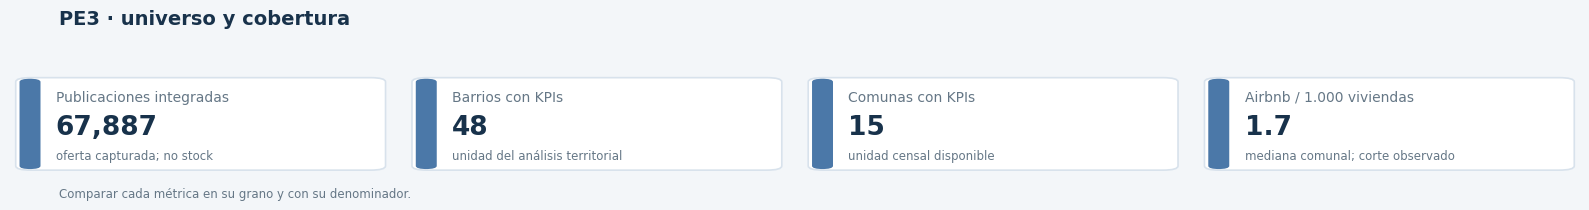

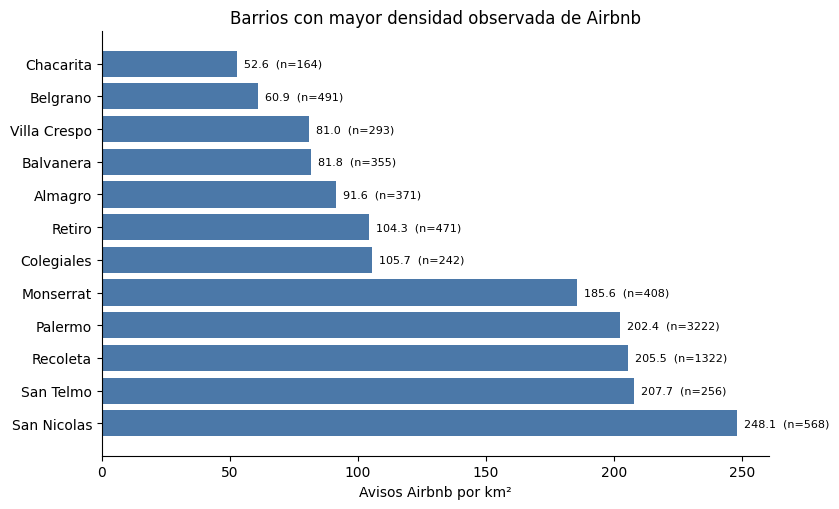

In [12]:
from src.pe3_visuals import kpi_cards
kpi_cards([
 ("Publicaciones integradas", f"{len(base):,}", "oferta capturada; no stock"),
 ("Barrios con KPIs", f"{kb['barrio_oficial'].nunique():,}", "unidad del análisis territorial"),
 ("Comunas con KPIs", f"{kc['comuna'].nunique():,}", "unidad censal disponible"),
 ("Airbnb / 1.000 viviendas", f"{kc['airbnb_por_1000_viviendas'].median():.1f}", "mediana comunal; corte observado"),
], title="PE3 · universo y cobertura", note="Comparar cada métrica en su grano y con su denominador.")
top = kb.dropna(subset=["airbnb_por_km2"]).nlargest(12, "airbnb_por_km2").sort_values("airbnb_por_km2")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
bars = ax.barh(top["barrio_oficial"], top["airbnb_por_km2"], color="#4b78a8")
for bar, (_, row) in zip(bars, top.iterrows()):
    ax.text(bar.get_width(), bar.get_y()+bar.get_height()/2,
            f"  {bar.get_width():.1f}  (n={int(row.get('n_airbnb', 0))})",
            va="center", fontsize=8)
ax.set_xlabel("Avisos Airbnb por km²")
ax.set_title("Barrios con mayor densidad observada de Airbnb")
ax.invert_yaxis()
for spine in ("top","right"): ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

**Cómo leerlo.** La densidad permite comparar intensidad territorial, mientras que `n` muestra cuánto sustenta cada barra. El ranking depende del área y de la cobertura de Airbnb; debe leerse junto con `airbnb_por_1000_viviendas`, alquiler permanente publicado y los límites de cobertura.